# Project 3. CLD Aggregation Tool

Last update: 05/16/2024

Title: Streamlining the Aggregation of Causal Loop Diagrams: A Thematic Labeling and Adjacency Matrix Approach

Overview: 
Spaghetti Causal Loop Diagrams (CLDs) present a significant challenge for modelers in effectively communicating complex system dynamics to stakeholders. Traditionally, modelers manually synthesize multiple CLDs to create an aggregated diagram that provides a higher-level understanding of the system. This paper introduces a streamlined procedure for aggregating CLDs using general categorical labels. 

The methodology involves translating qualitative mental models into adjacency matrices that capture both links and polarity signs, manually coding and substituting variable names with thematic labels, aggregating these matrices to identify significant feedback loops, and validating the approach by comparing it with the manual synthesis performed by an expert system dynamicist. 

Our results demonstrate that this tool is highly useful for group model-building experts, particularly when dealing with a large number of mental maps. The proposed method enhances the clarity and efficiency of synthesizing complex CLDs, thereby improving the overall communication of system dynamics.







In [112]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [113]:
import numpy as np
import os 
import pickle
import pandas as pd
import sys
import networkx as nx

# Add the src directory to the sys.path
sys.path.append(os.path.abspath(os.path.join('..', 'src')))

# Import the function from data_io.py
from data_io import read_json
# from parse_cld import get_dataframe, get_adjacency_matrix, get_polarity_matrix
import parse_cld 


In [114]:
# Set the new directory
new_dir = "/Users/gl665/PycharmProjects/Phrame_MentalMaps"
# Change the current working directory
os.chdir(new_dir)

print(os.getcwd())

/Users/gl665/PycharmProjects/Phrame_MentalMaps


In [121]:
# Read all the json files in 
my_data_RC = {}
folder_path = 'Output/SYNCH/JSON_file/RC/'

my_data_RC = read_json(folder_path, my_data_RC)

Output/SYNCH/JSON_file/RC/FM 51220Clean.json
load: FM 51220Clean.json
Output/SYNCH/JSON_file/RC/Passages Clean.json
load: Passages Clean.json
Output/SYNCH/JSON_file/RC/full circle GBM 5 24 21clean.json
load: full circle GBM 5 24 21clean.json
Output/SYNCH/JSON_file/RC/C 7 6 20 clean model.json
load: C 7 6 20 clean model.json
Output/SYNCH/JSON_file/RC/tracy clean model.json
load: tracy clean model.json
Output/SYNCH/JSON_file/RC/Wavi combined clean.json
load: Wavi combined clean.json
Output/SYNCH/JSON_file/RC/drug justice model clean.json
load: drug justice model clean.json
Output/SYNCH/JSON_file/RC/7 13 20 clean model.json
load: 7 13 20 clean model.json
Output/SYNCH/JSON_file/RC/DSS23.json
load: DSS23.json
Output/SYNCH/JSON_file/RC/E clean model 572020.json
load: E clean model 572020.json
Output/SYNCH/JSON_file/RC/nat model clean2.json
load: nat model clean2.json
Output/SYNCH/JSON_file/RC/j model 7 13 20 clean model3.json
load: j model 7 13 20 clean model3.json
Output/SYNCH/JSON_file/RC/

In [ ]:
# file_rename = pd.read_excel('Output/SYNCH/file_rename/RC_file_rename.xlsx', index_col=0)
# file_rename['file_no.'] = [i+1 for i in range(len(file_rename.index))]
# file_rename.head(3)



In [39]:
# df_rc_themes = pd.read_excel('Dataset/SYNCH/aggregate_theme/RC_Updated_Themes.xlsx', sheet_name= "clean")

# # get column 1 and 4
# df_aggregate_names = df_rc_themes.iloc[:, [1, 4]]

# df_aggregate_names.columns = ['theme', 'variable']
# # delete rows if both are column values are nan 
# df_aggregate_names = df_aggregate_names.dropna(subset=['theme', 'variable'], how='all')


# df_aggregate_names['theme'] = df_aggregate_names['theme'].fillna(method='ffill')

# df_aggregate_names['theme']= df_aggregate_names['theme'].str.lower()
# df_aggregate_names['variable']= df_aggregate_names['variable'].str.lower()

# df_aggregate_names.head(20)
# df_aggregate_names.to_csv('Dataset/SYNCH/aggregate_theme/RC_theme_var_matching.csv', index=False)

df_aggregate_names = pd.read_csv('Dataset/SYNCH/aggregate_theme/RC_theme_var_matching.csv')
df_aggregate_names.head()

,theme,variable
0,healthy development,child psychological development
1,healthy development,healthy child development
2,healthy development,child behavioral issues
3,healthy development,child physcial violent perpetration
4,healthy development,developmental delay in child


In [139]:
dict_pol_mx = {}
for key, value in my_data_RC.items():
    # print(key, value)
    pol_mx = parse_cld.get_theme_cld(value, df_aggregate_names)
    print(pol_mx.shape)
    dict_pol_mx[key] = pol_mx 



#  pol_max_combined = parse_cld.get_combine_matrix(pol_mx, )

(130, 130)
(21, 21)
(138, 138)
(89, 89)
(130, 130)
(36, 36)
(129, 129)
(18, 18)
(48, 48)
(95, 95)
(154, 154)
(108, 108)
(153, 153)
(86, 86)
(79, 79)
(40, 40)
(72, 72)
(17, 17)
(167, 167)


In [140]:
# pol_max_combined = pd.DataFrame()
df = pd.DataFrame()

# combined all the dataframe in  dict_pol_mx using get_combined_matrix 


for key, value in dict_pol_mx.items():
    print(key)
    pol_max_combined = parse_cld.get_combine_matrix(value, df)


FM 51220Clean.json
Passages Clean.json
full circle GBM 5 24 21clean.json
C 7 6 20 clean model.json
tracy clean model.json
Wavi combined clean.json
drug justice model clean.json
7 13 20 clean model.json
DSS23.json
E clean model 572020.json
nat model clean2.json
j model 7 13 20 clean model3.json
FC Prov Clean.json
full circle clean.json
reentry clean model.json
1 6 21 Legal clean.json
DV justice model clean.json
SOC clean.json
RC 4 28 2021 Clean.json


In [153]:
pol_max_combined.shape

# Check if the matrix is sqaure 
if (pol_max_combined.shape[0] == pol_max_combined.shape[1]): 
    print("true")
else: 
    print('false')

# pol_max_combined.to_excel('tt.xlsx')



true


In [178]:
tt = pd.read_excel('tt.xlsx')
tt.index = tt['from']
# delete first column 
tt = tt.drop(columns=['from'])

# fill nan with 0 
tt = tt.fillna(0)
tt

,alcohol use,early onset of alcohol use,early onset of drug use,parental supervision and monitoring,early sexual activity,healthfulness of child-rearing practices,aces,learning about healthy relationships,forming relationships with negative (risk taking) peers,negative peer influence,...,programs that reach out to people,non-judgemental encouraging treatment,non-judgemental encouraging treatment.1,non-judgemental encouraging treatment.2,completing substance use treatment.1,commitment to sobriety,using sobriety-maintaining resources,availability of sobriety-maintaining resources,sober social support,asking court for help for drug use
from,,,,,,,,,,,,,,,,,,,,,
alcohol use,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
early onset of alcohol use,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
early onset of drug use,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
parental supervision and monitoring,0,1,1,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
early sexual activity,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
commitment to sobriety,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
using sobriety-maintaining resources,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
availability of sobriety-maintaining resources,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [179]:
import networkx as nx

# Assuming you have a DataFrame 'df' with NaN values in column names or index labels
tt = tt.rename(columns=lambda x: str(x) if pd.notnull(x) else 'missing_column')
tt = tt.rename(index=lambda x: str(x) if pd.notnull(x) else 'missing_index')

# Create a NetworkX graph from the cleaned DataFrame
# G = nx.from_pandas_adjacency(df)

G= nx.from_pandas_adjacency(tt, create_using=nx.DiGraph)

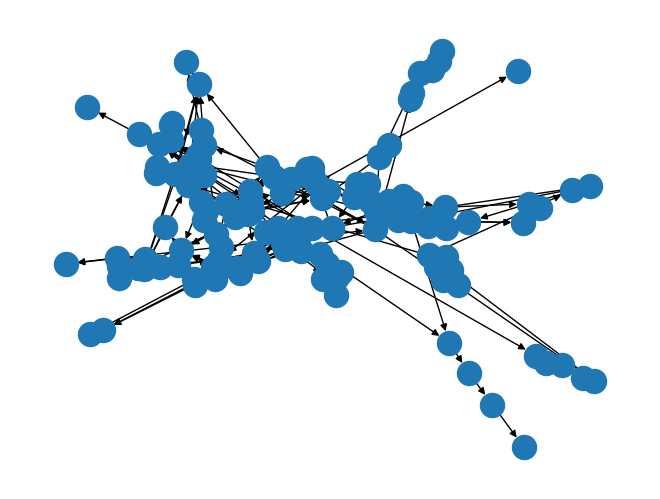

In [180]:
import matplotlib.pyplot as plt

nx.draw(G)
plt.draw()

## get one pol_mx using the get_theme_cld function

In [42]:
pol_mx = parse_cld.get_theme_cld(my_data_RC['Passages Clean.json'], df_aggregate_names)
print(pol_mx)

to                                     intimate partner violence  \
from                                                               
intimate partner violence                                      0   
relationship functioning                                       1   
passages (re-entry facility)                                   0   
healing                                                        0   
supportive people                                              0   
accountablility                                                0   
drugs                                                          1   
alcohol exposed pregnancy                                      0   
emotional distress                                             0   
family functioning                                             0   
dire situtations                                               0   
jail/incarceration                                             0   
mental health                                   

## Get an aggregated CLD for one single CLD 

In [ ]:
dict_vars, df = parse_cld.get_dataframe(my_data_RC['Passages Clean.json'])


Take "Rapid City Update Themes" Excel Sheet "Clean" column B for Aggregated Variable Name and column E for orignial Variable name

In [ ]:
# create a dataframe for the single cld var name and the theme 
# create a pd datframe 
vars_cld = pd.DataFrame.from_dict(dict_vars, orient='index').reset_index()
# rename columns 
vars_cld.columns = ['vensim_var_no','var_name']
# turn all the variable names to lowercap 
vars_cld['var_name'] = vars_cld['var_name'].str.lower()
# delete the "" sign 
vars_cld['var_name'] = vars_cld['var_name'].str.replace('"', '')
vars_cld.head(10)

In [ ]:
# merge the two dataframes and find the theme name for the cld 
df_aggregate_merge = pd.merge(df_aggregate_names, vars_cld, left_on='variable', right_on='var_name', how='right')
# df_aggregate_merge

In [ ]:
# create a new dictionary the keys in the vensim vars no, the values is the theme column, if the value is nan, the value is variable 
theme_dict = {}
for index, row in df_aggregate_merge.iterrows():
    if pd.isna(row['theme']):
        theme_dict[row['vensim_var_no']] = row['var_name']
    else:
        theme_dict[row['vensim_var_no']] = row['theme']

# theme_dict

In [ ]:
# merging the cld. Count the duplicate themes. 

df_aggregate_merge['vensim_var_no'] = df_aggregate_merge['vensim_var_no'].astype(int)
# create a new variable number for the theme 

# def get_duplicate_theme_no(df):
#     # get all the duplicate theme no 
#     df_theme_no = df['theme'].value_counts()
#     duplicate_theme_no = df_theme_no[df_theme_no > 1].index.tolist()
#     return duplicate_theme_no

list_of_duplicate_themes = parse_cld.get_duplicate_theme_no(df_aggregate_merge)
print(list_of_duplicate_themes)


In [ ]:

# create a dictionary where the keys is the orignial var_no and the new var_no is the theme_no

theme_no_dict = {}
for i, val in enumerate(list_of_duplicate_themes):
    theme_no_dict[val] = max(df_aggregate_merge['vensim_var_no']) + i + 1

df_aggregate_merge['theme_no'] = df_aggregate_merge['theme'].map(theme_no_dict)


for i, row in df_aggregate_merge.iterrows():
    if pd.isna(row['theme_no']):
        df_aggregate_merge.at[i, 'theme_no'] = row['vensim_var_no']


df_aggregate_merge['theme_no'] = df_aggregate_merge['theme_no'].astype(int)

# df_aggregate_merge



In [ ]:
theme_org_new_dict = dict(zip(df_aggregate_merge['vensim_var_no'], df_aggregate_merge['theme_no']))


In [ ]:
new_df = df.copy()
# change all data in df to int 
new_df = new_df.astype(int)
#swap the from column in df to new number based on theme_no_number_dict
new_df['from'] = new_df['from'].map(theme_org_new_dict)
new_df['to'] = new_df['to'].map(theme_org_new_dict)

merge_df = new_df.groupby(['from', 'to']).sum().reset_index()

# merge_df


In [ ]:
pol_mx = parse_cld.get_adjacency_matrix(merge_df)
# change theme dict keys to int 
theme_dict = {int(k): v for k, v in theme_dict.items()}
# theme_dict

In [ ]:
# merge the same theme frame??  

# pol_mx = parse_cld.get_adjacency_matrix(df)

pol_mx.columns = pol_mx.columns.map(theme_dict)

pol_mx.index = pol_mx.index.map(theme_dict)
pol_mx


## Combining Matrices 

In [117]:

matrix1 = [[ 1, 1, 1, 0, 1],
        [1, 0, 1, 1, 1],
        [ 1, 0, 0, 0, 0],
        [1, 1, 0, 1, 0],
        [1, 0, 0, 1, 0]]

matrix1 = pd.DataFrame(matrix1, columns=['a', 'b', 'c', 'd', 'e'])
matrix1.index = rows_1
print(matrix1)



matrix2 = [[ 0, 1, 1, 0, 1],
        [1, 0, 1, 1, 1],
        [ 1, 0, 0, 0, 0],
        [1, 1, 0, 1, 0],
        [1, 0, 0, 1, 1]]

matrix2 = pd.DataFrame(matrix2, columns=['z', 'd', 'c', 'b', 'a'])
matrix2.index = rows_2
print("matrix2")
print(matrix2)

   a  b  c  d  e
a  1  1  1  0  1
b  1  0  1  1  1
c  1  0  0  0  0
d  1  1  0  1  0
e  1  0  0  1  0
matrix2
   z  d  c  b  a
z  0  1  1  0  1
d  1  0  1  1  1
c  1  0  0  0  0
b  1  1  0  1  0
a  1  0  0  1  1


In [119]:
# def combine_non_nan(s1, s2):
#     # print("s1", s1)
#     # print("s2", s2)
#     if pd.isna(s1).all():
#         return s2
#     elif pd.isna(s2).all():
#         return s1
#     else:
#         return s1 + s2



# def get_combine_matrix(matrix1, matrix2): 

#     combined_matrix = matrix1.combine(matrix2, combine_non_nan, overwrite = False)
#     combined_matrix = combined_matrix.fillna(matrix1)
#     combined_matrix = combined_matrix.fillna(matrix2)

#     return combined_matrix 

combined_matrix = parse_cld.get_combine_matrix(matrix1, matrix2)
print(combined_matrix)

     a    b    c    d    e    z
a  2.0  2.0  1.0  0.0  1.0  1.0
b  1.0  1.0  1.0  2.0  1.0  1.0
c  1.0  0.0  0.0  0.0  0.0  1.0
d  2.0  2.0  1.0  1.0  0.0  1.0
e  1.0  0.0  0.0  1.0  0.0  NaN
z  1.0  0.0  1.0  1.0  NaN  0.0


In [161]:
combined_matrix_ = np.where(combined_matrix == 2, 1, combined_matrix)



(6, 7)


NameError: name 'plt' is not defined

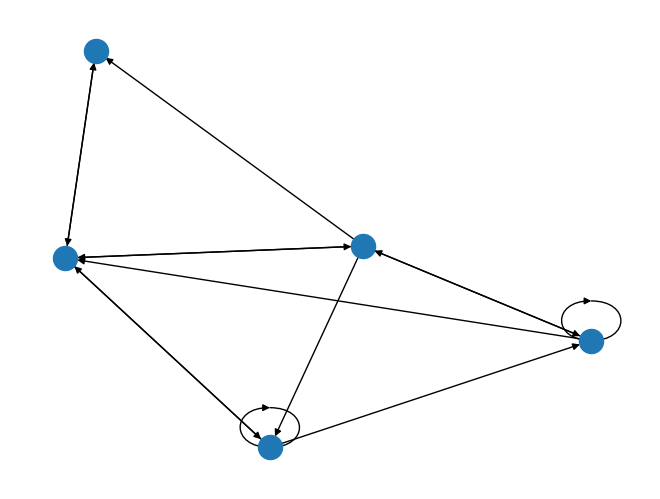

In [165]:
# import cld_nx
print(combined_matrix.shape)
combined_matrix = combined_matrix.reset_index()
G= nx.from_pandas_adjacency(matrix2, create_using=nx.DiGraph)
nx.draw(G)
plt.draw()